In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset_Citation_Request.txt


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Read Dataset
file_path = '/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff'

data, meta = arff.loadarff(file_path)

df = pd.DataFrame(data)

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.decode('utf-8')

print(df.head())
print("Dataset Shape:", df.shape)


      Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395.0    610.291       208.178117       173.888747      1.197191   
1  28734.0    638.018       200.524796       182.734419      1.097356   
2  29380.0    624.110       212.826130       175.931143      1.209713   
3  30008.0    645.884       210.557999       182.516516      1.153638   
4  30140.0    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812     28715.0     190.141097  0.763923  0.988856   0.958027   
1      0.411785     29172.0     191.272750  0.783968  0.984986   0.887034   
2      0.562727     29690.0     193.410904  0.778113  0.989559   0.947849   
3      0.498616     30724.0     195.467062  0.782681  0.976696   0.903936   
4      0.333680     30417.0     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358    

In [3]:

X = df.drop('Class', axis=1).values
y = df['Class'].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (13611, 16)
Target Shape: (13611,)


In [4]:

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded Classes:", np.unique(y))


Classes: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']
Encoded Classes: [0 1 2 3 4 5 6]


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


Training Shape: (10888, 16)
Testing Shape: (2723, 16)


In [6]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling Completed!")


Scaling Completed!


In [7]:

num_classes = len(np.unique(y_train))

Y_train = np.eye(num_classes)[y_train]

print("Number of Classes:", num_classes)
print("Y_train Shape:", Y_train.shape)


Number of Classes: 7
Y_train Shape: (10888, 7)


In [8]:

np.random.seed(42)

n_samples, n_features = X_train.shape

W = np.random.randn(n_features, num_classes) * 0.01
b = np.zeros(num_classes)

# Momentum variables
vW = np.zeros_like(W)
vb = np.zeros_like(b)

print("Weights Shape:", W.shape)
print("Bias Shape:", b.shape)


Weights Shape: (16, 7)
Bias Shape: (7,)


In [9]:

def softmax(z):
    z = z - np.max(z)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)


def compute_loss(Y_true, Y_pred):
    epsilon = 1e-15
    Y_pred = np.clip(Y_pred, epsilon, 1 - epsilon)

    return -np.mean(
        np.sum(Y_true * np.log(Y_pred), axis=1)
    )


In [10]:

# Hyperparameters

learning_rate = 0.01
epochs = 100
beta = 0.9

loss_history = []

# SGD Training

for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(n_samples)

    for i in indices:

        # Select one sample
        x_i = X_train[i]
        y_i = Y_train[i]

        # Forward Propagation
        z = np.dot(x_i, W) + b
        y_pred = softmax(z)

        # Calculate Error
        error = y_pred - y_i

        # Calculate Gradient
        dW = np.outer(x_i, error)
        db = error

        # Momentum Update
        vW = beta * vW + dW
        vb = beta * vb + db

        # Update Weights and Bias
        W -= learning_rate * vW
        b -= learning_rate * vb

    # Calculate Loss after each Epoch
    z_all = np.dot(X_train, W) + b

    exp_z = np.exp(
        z_all - np.max(z_all, axis=1, keepdims=True)
    )

    y_all_pred = exp_z / np.sum(
        exp_z, axis=1, keepdims=True
    )

    loss = compute_loss(Y_train, y_all_pred)

    loss_history.append(loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

print("SGD Training Completed!")


Epoch 10, Loss: 0.2356
Epoch 20, Loss: 0.2389
Epoch 30, Loss: 0.2481
Epoch 40, Loss: 0.2329
Epoch 50, Loss: 0.2299
Epoch 60, Loss: 0.2352
Epoch 70, Loss: 0.2474
Epoch 80, Loss: 0.2306
Epoch 90, Loss: 0.2435
Epoch 100, Loss: 0.2439
SGD Training Completed!


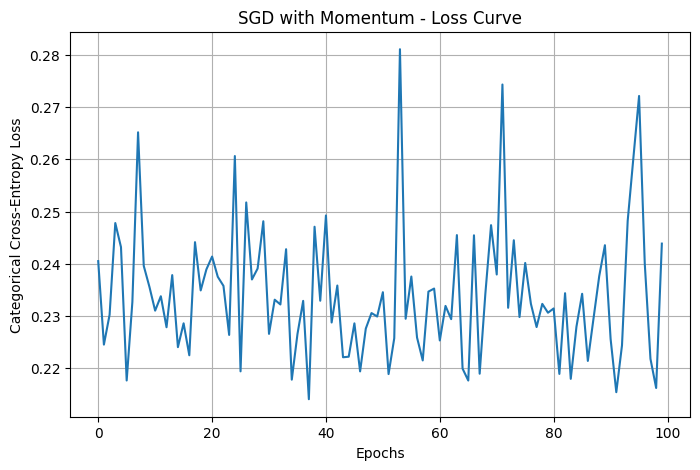

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title('SGD with Momentum - Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Categorical Cross-Entropy Loss')

plt.grid(True)
plt.show()


In [12]:

z_test = np.dot(X_test, W) + b

exp_z = np.exp(
    z_test - np.max(z_test, axis=1, keepdims=True)
)

y_test_prob = exp_z / np.sum(
    exp_z, axis=1, keepdims=True
)

y_pred = np.argmax(y_test_prob, axis=1)

print("Predicted:", y_pred[:10])
print("Actual:", y_test[:10])


Predicted: [3 1 6 5 0 5 3 6 2 4]
Actual: [3 1 6 5 0 5 3 6 0 4]


In [13]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='macro'
)

recall = recall_score(
    y_test, y_pred, average='macro'
)

f1 = f1_score(
    y_test, y_pred, average='macro'
)

print("SGD with Momentum Results")
print("-------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


SGD with Momentum Results
-------------------------
Accuracy:  0.9148
Precision: 0.9312
Recall:    0.9259
F1 Score:  0.9274


In [14]:

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))


              precision    recall  f1-score   support

    BARBUNYA       0.97      0.88      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.96      0.92       326
    DERMASON       0.93      0.90      0.91       709
       HOROZ       0.98      0.89      0.93       386
       SEKER       0.91      0.97      0.94       406
        SIRA       0.83      0.89      0.86       527

    accuracy                           0.91      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.91      0.92      2723



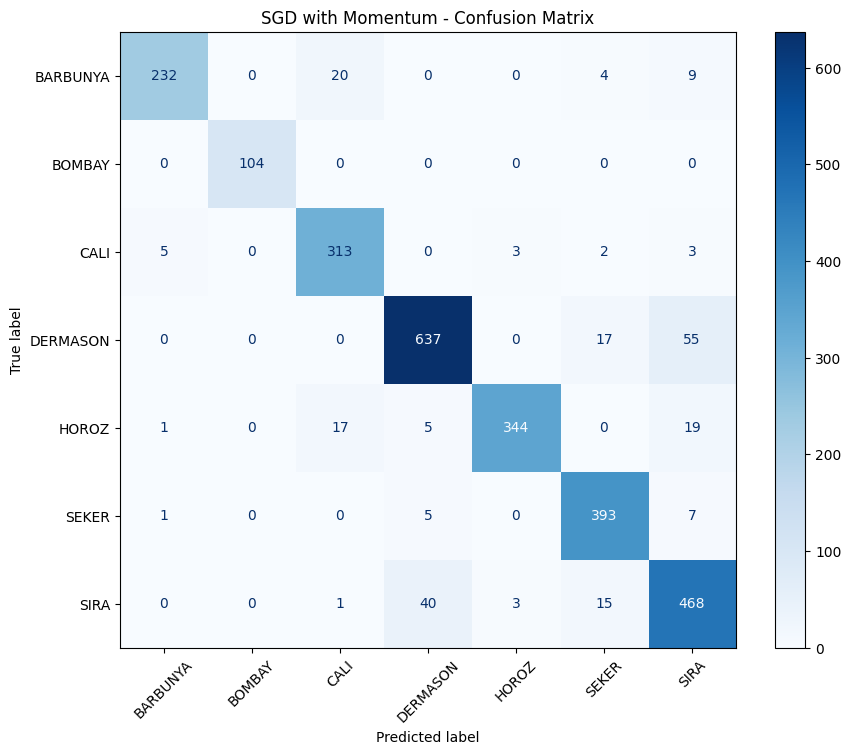

In [15]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap='Blues',
    xticks_rotation=45,
    ax=ax
)

plt.title('SGD with Momentum - Confusion Matrix')
plt.show()


In [16]:

sgd_results = {
    'Optimizer': 'SGD with Momentum',
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1,
    'Loss': loss_history[-1]
}

results_df = pd.DataFrame([sgd_results])

print(results_df)


           Optimizer  Accuracy  Precision    Recall  F1 Score      Loss
0  SGD with Momentum    0.9148   0.931226  0.925894  0.927436  0.243859
